# TP2 : interpolation polynomiale

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Différences divisées

On rappelle que les différences divisées sont définies par récurrence par :
$$ f[x_i] = f(x_i),\quad\text{et}\quad f[x_i,\dotsc,x_{i+k}] = \frac{f[x_{i+1},\dotsc,x_{i+k}] - f[x_i,\dotsc,x_{i+k-1}]}{x_{i+k} - x_i} $$

1. Écrire une fonction `diff_div` qui calcule le tableau des différences divisées. Écrire la fonction de sorte à ce qu'il n'y ait qu'une seule boucle (vectoriser le calcul de la colonne $k+1$ à partir de la colonne $k$).
2. Tester cette fonction avec $f(x) = \frac{1}{1+x^2}$ sur les nœuds -1, 0, 1 et 2. On doit trouver sur la première ligne du tableau des différences divisées 0.5, 0.5, -0.5, 0.2.

In [2]:
def diff_div(x, y):
    """
    x, y : vecteurs numpy de même taille (nœuds x_i et valeurs f(x_i))
    Renvoie un tableau contenant les différences divisées
    f[x_i, x_{i+1}, ..., x_{i+k}]
    """
    n = x.size
    D = np.zeros((n, n))
    D[:,0] = y # la première colonne du tableau contient les valeurs y_i
    for k in range(1, n):
        D[0:n-k, k] = (D[1:n-k+1, k-1] - D[0:n-k, k-1]) / (x[k:n] - x[0:n-k])
        # avec du slicing, on peut vectoriser les calculs
        # et éviter d'écrire une 2e boucle suivante.
        # La ligne ci-dessus est l'équivalent de la boucle :
        #for i in range(n-k):
        #    D[i,k] = (D[i+1,k-1] - D[i,k-1]) / (x[i+k] - x[i]) 
    return D

In [3]:
def f(x): 
    return 1/(1+x**2)

noeuds = np.array([-1, 0, 1 ,2]) # c'est un vecteur, pas juste une liste
y = f(noeuds) # f est vectorisée, elle s'applique à chaque élément du vecteur
D = diff_div(noeuds, y)
print(D)

[[ 0.5  0.5 -0.5  0.2]
 [ 1.  -0.5  0.1  0. ]
 [ 0.5 -0.3  0.   0. ]
 [ 0.2  0.   0.   0. ]]


On retrouve bien le tableau des différences divisées de l'exemple du cours :
$$\begin{array}{r|r|r|r|r}
x_i & f(x_i) & f[x_i, x_{i+1}] & f[x_i,x_{i+1},x_{i+2}] & f[x_i,x_{i+1},x_{i+2},x_{i+3}] \\\hline
-1 & 0.5 & 0.5 & -0.5 & 0.2 \\
0 & 1 & -0.5 & 0.1 &  \\
1 & 0.5 & -0.3 &  &  \\
2 & 0.2 &  & & \\
\end{array}$$

## Méthode de Horner

Le polynôme interpolateur de $f$ s'écrit dans la base de Newton :
$$ P(x) = c_0 + \sum_{k=1}^{n} c_k N_k(x),\quad N_k(x) = \prod_{i=0}^{k-1} (x-x_i), $$
avec $c_k = f[x_0,\dotsc,x_k]$ les différences divisées.

La méthode de Horner permet d'évaluer efficacement $P$ en tirant parti des facteurs communs dans les $N_k$. Le principe est le suivant : tous les $N_k$ ont pour facteur commun $x-x_0$, donc on peut écrire :
$$ P(x) = c_0 + (x-x_0)P_1(x) $$
avec :
$$ P_1(x) = c_1 + \sum_{k=2}^n c_k\prod_{i=1}^{k-1} (x-x_i).$$
Le polynôme $P_1$ a la même "structure" que $P$, donc on peut recommencer le procédé : on factorise la somme par $x-x_1$ et on obtient :
$$ P_1(x) = c_1 + (x-x_1)P_2(x)$$
avec :
$$ P_2(x) = c_2 + \sum_{k=3}^n c_k \prod_{i=2}^{k-1} (x-x_i). $$
etc. 

Plus formellement, la méthode de Horner calcule $P(x)$ par récurrence descendante. On pose $P_n(x) = c_n$ et :
$$ \forall k\in\{n-1,n-2,\dotsc,0\},\quad  P_{k}(x) = c_k + (x-x_k)P_{k+1}(x).$$
La valeur cherchée est $P_0(x)$.

1. Écrire une fonction `Horner` qui permet d'évaluer $P$ sur un vecteur de points $x$, en utilisant la méthode de Horner.
2. Tester cette fonction avec le polynôme interpolateur de $f(x) = \frac{1}{1+x^2}$ sur les nœuds $-1, 0, 1, 2$. On pourra tester sur le vecteur $x=(-1,0,1,2)$ pour voir si on a bien interpolé $f$.

In [4]:
def Horner(x, coeff, nodes):
    """
    x : vecteur de points d'évaluation
    coeff : coefficients c_0, ..., c_n issus de diff_div
    nodes : nœuds x_0, ..., x_n
    Renvoie le vecteur P(x) des évaluations de P
    """
    n = coeff.size - 1
    P = coeff[n] * np.ones(x.size) # initialise P comme un vecteur 
    # de même taille que x dont toutes les valeurs sont c_n.
    # np.ones(x.size) crée un vecteur contenant des 1 de même taille que x
    # et on le multiplie par c_n.
    for k in range(n - 1, -1, -1): # k décroit de n-1 à 0 
                                   # range(a,b,s) : de a (inclus) à b (exclu)
                                   # par pas de s
        P = coeff[k] + (x - nodes[k]) * P
    return P

In [5]:
# on rappelle que les coefficients c_k sont dans 
# la première ligne du tableau des différences divisées
noeuds = np.array([-1, 0, 1, 2])
D = diff_div(noeuds, f(noeuds))
print("f(x_i) =", f(noeuds))
print("P(x_i) =", Horner(noeuds, D[0], noeuds))
# on doit trouver P(x_i) = f(x_i)

f(x_i) = [0.5 1.  0.5 0.2]
P(x_i) = [0.5 1.  0.5 0.2]


Pour la suite, écrire une fonction `interpol` qui évalue directement le polynôme interpolateur sur un vecteur $x$, à partir des nœuds $x_i$ et des valeurs $f(x_i)$.

In [6]:
def interpol(x, nodes, val):
    coeff = diff_div(nodes, val)[0] # première ligne du tableau
    return Horner(x, coeff, nodes)

## Phénomène de Runge

On considère la fonction $f(x) = \frac{1}{1+25x^2}$ sur l'intervalle $[-1, 1]$.

1. Pour $n \in \{ 7,8,9,10\}$, calculer le polynôme interpolateur de $f$ sur $n+1$ nœuds équidistants de $[-1, 1]$.
2. Tracer dans un même graphique $f$ et les polynômes d'interpolation.
3. Tracer $\lVert f - P_n \rVert_\infty$ pour $n$ allant de 2 à 30 dans un repère semi-log.

In [7]:
def g(x): 
    return 1/(1 + 25 * x**2)

n_val = np.array([7, 8, 9, 10])
x = np.linspace(-1, 1, 200) # points d'évaluation, pour le graphique
P = np.zeros(shape=(n_val.size, x.size)) # matrice qui contiendra les 
# résultats : chaque ligne contient un polynôme interpolateur, 
# évalué en tout point du vecteur x.

for i, n in enumerate(n_val):
    noeuds = np.linspace(-1, 1, n + 1)
    P[i,:] = interpol(x, noeuds, g(noeuds))

# Astuce python :
# si n_val = [7, 8, 9, 10]
# enumerate(n_val) produit successivement 
# (0, 7), (1, 8), (2, 9), (3, 10).
# Dans la boucle "for i, n in enumerate(n_val)",
# l'indice i compte l'itération courante, et n la valeur courante dans
# la liste n_val

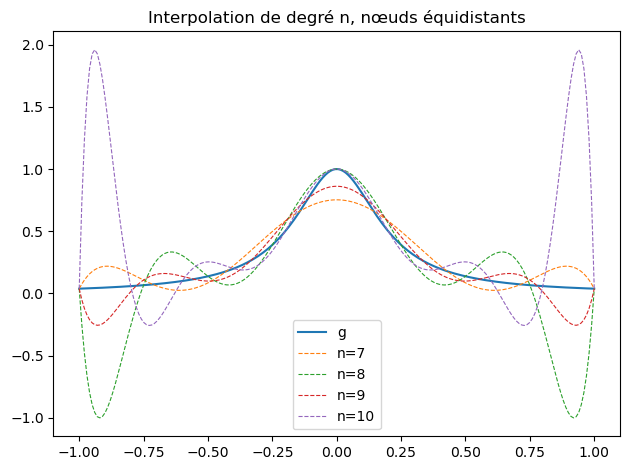

In [8]:
plt.plot(x, g(x), label = "g")
for i, n in enumerate(n_val):
    plt.plot(x, P[i], "--", linewidth=0.8, label = f"n={n}")
plt.legend()
plt.title("Interpolation de degré n, nœuds équidistants")
plt.tight_layout()
plt.show()

On observe de fortes oscillations au bord de l'intervalle, dont l'amplitude augmente avec $n$. C'est le phénomène de Runge.

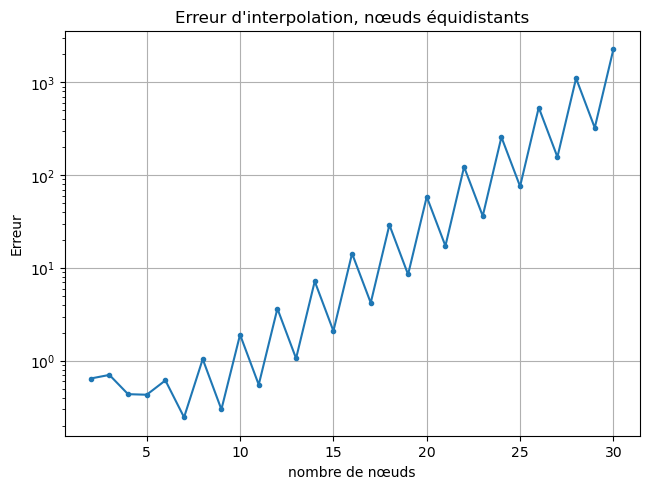

In [9]:
n_val = np.arange(2, 31)
x = np.linspace(-1, 1, 200)
P = np.zeros((n_val.size, x.size))
for i, n in enumerate(n_val):
    noeuds = np.linspace(-1, 1, n + 1)
    P[i,:] = interpol(x, noeuds, g(noeuds))

erreur_equid = np.max(np.abs(g(x) - P), axis=1)
# On vectorise les calculs pour éviter d'écrire des boucles.
# f(x) : vecteur de 200 points
# P : matrice (29, 200), chaque ligne contient les évaluations d'un polynôme
# np.abs(g(x) - P) : matrice (29, 200), chaque ligne contient les écarts entre
#                    g et un polynôme, sur 200 points
# np.max(np.abs(g(x) - P), axis=1) : vecteur de taille 29, 
#                                    calcule le maximum sur chaque ligne
# le axis=1 signifie que le max est pris par rapport à l'indice des colonnes
# (l'indice "0" est celui des lignes, l'indice "1" est celui des colonnes)
# si M est la matrice (29, 200) des écarts précédents, alors cette syntaxe
# est l'équivalent de la boucle :
# for i in range(29):
#    erreur[i] = np.max(M[i,:])

plt.plot(n_val, erreur_equid, ".-")
plt.yscale('log')
plt.title("Erreur d'interpolation, nœuds équidistants")
plt.grid()
plt.tight_layout()
plt.xlabel("nombre de nœuds")
plt.ylabel("Erreur")
plt.show()

Pour des nœuds équidistants, la suite des polynômes interpolateurs ne converge pas vers $f$ (on observe même une divergence à vitesse exponentielle !). 

## Nœuds de Tchebychev

On rappelle que les nœuds de Tchebychev sur $[-1,1]$ sont donnés par :
$$ \forall i\in\{0,1,\dotsc,n\},\quad x_i = \cos\left(\frac{(2i+1)\pi}{2n+2}\right)$$

1. Écrire une fonction `tchebychev` qui calcule les nœuds de Tchebychev.
2. Refaire les questions de la partie précédente, avec les nœuds de Tchebychev.

In [10]:
def tchebychev(n):
    i = np.arange(n + 1)
    return np.cos((2 * i + 1) * np.pi / (2 * n + 2))
# les calculs sont vectorisés
# i est un vecteur contenant les entiers de 0 à n (le n+1 est exclu)
# la ligne suivante effectue le calcul sur chaque élément de i
# on obtient donc un vecteur contenant les nœuds de Tchebychev.

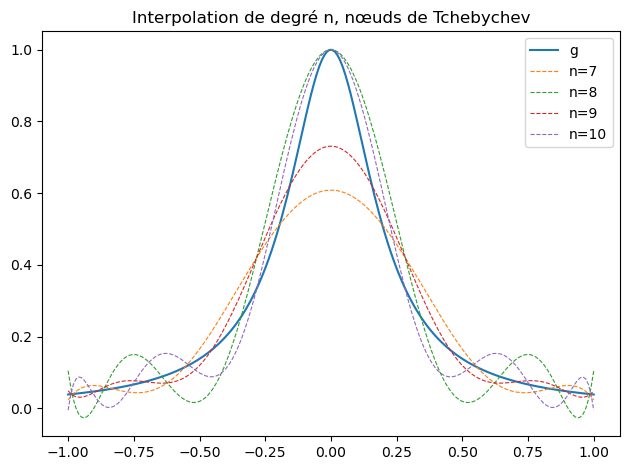

In [11]:
n_val = np.array([7, 8, 9, 10])
x = np.linspace(-1, 1, 200)
plt.plot(x, g(x), label = "g")
for n in n_val:
    noeuds = tchebychev(n)
    P = interpol(x, noeuds, g(noeuds))
    plt.plot(x, P, "--", linewidth=0.8, label = f"n={n}")
plt.legend()
plt.title("Interpolation de degré n, nœuds de Tchebychev")
plt.tight_layout()
plt.show()

Contrairement au cas des nœuds équidistants, les oscillations au bord disparaissent.

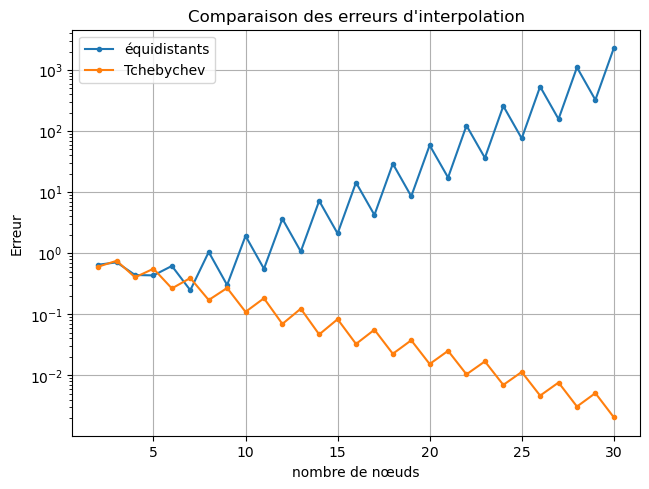

In [12]:
n_val = np.arange(2, 31)
x = np.linspace(-1, 1, 200)
erreur_tcheb = np.zeros(n_val.size)
for i, n in enumerate(n_val):
    noeuds = tchebychev(n)
    P = interpol(x, noeuds, g(noeuds))
    erreur_tcheb[i] = np.max(np.abs(g(x) - P))

plt.plot(n_val, erreur_equid, ".-", label="équidistants")
plt.plot(n_val, erreur_tcheb, ".-", label="Tchebychev")
plt.yscale("log")
plt.title("Comparaison des erreurs d'interpolation")
plt.legend()
plt.grid()
plt.tight_layout()
plt.xlabel("nombre de nœuds")
plt.ylabel("Erreur")
plt.show()

L'erreur pour les nœuds de Tchebychev décroit à vitesse géométrique, mais la décroissance est lente : avec 30 nœuds, l'ordre de grandeur de l'erreur n'est que de $10^{-3}$.

## Bonus : vitesse de décroissance de l'erreur

Pour une décroissance géométrique, l'erreur décroit comme :
$$ e_n \approx C q^n $$
donc $\log(e_n) \approx n \log(q) + \log(C)$. Les points $(n, \log(e_n))$ sont approximativement alignés, sur une droite de pente $\log(q)$, avec $q$ la raison de la suite.

La fonction `np.polyfit` permet de calculer la "meilleure" droite (plus généralement le "meilleur" polynôme) passant parmi des points. Elle revoie le coefficient directeur et l'ordonnée à l'origine de la droite en question (plus généralement, elle renvoie le vecteur des coefficients du polynôme, en commençant par le coefficient dominant).

In [13]:
log_q = np.polyfit(n_val, np.log(erreur_tcheb), deg=1)[0]
print("q =", np.exp(log_q))

q = 0.8199389811131073


La vitesse de décroissance de l'erreur est $q^n$ avec $q\approx 0.82$. Vérfification :

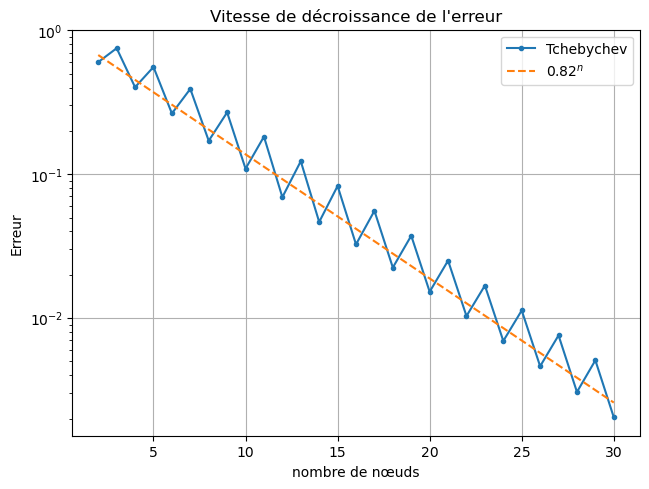

In [14]:
q = np.exp(log_q)
plt.plot(n_val, erreur_tcheb, ".-", label="Tchebychev")
plt.plot(n_val, q ** n_val, "--", label=f"${q:.2f}^n$")
plt.yscale("log")
plt.title("Vitesse de décroissance de l'erreur")
plt.legend()
plt.grid()
plt.tight_layout()
plt.xlabel("nombre de nœuds")
plt.ylabel("Erreur")
plt.show()